# **Session 7**

## Data Visualisation with Plots

In Session 6 we described the data using **numbers** (mean, median, std, counts).
Today we turn those numbers into **pictures**. A good plot can show patterns, outliers and relationships very quickly.

For every plot we will ask three simple questions:

1. **What does it show?**
2. **When do we use it?**
3. **How do we make it in Python?**



## Part 1: Recap and Setup

First we load the data, exactly like before.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!ls "/content/drive/MyDrive/Colab Notebooks/Data/"

import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Data/academic_data.csv")

Mounted at /content/drive
academic_data.csv


### Import the plotting libraries

| Library | Short name | What it does |
|---|---|---|
| `matplotlib.pyplot` | `plt` | The main plotting library. Titles, labels and showing the plot. |
| `seaborn` | `sns` | Built on matplotlib. It gives us nicer plots like pair plot and heatmap with one line of code. |

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

### Quick recap of Session 6 (cleaning)

We make a copy of the data and fix the two small problems we found: the empty `ai_tool` cells and the dash in `complaint_type`.

In [3]:
df_clean = df.copy()

df_clean["ai_tool"] = df_clean["ai_tool"].fillna("No Tool")

df_clean.head()

,student_id,name,gender,age,year,section,study_hours,attendance,ai_usage_hours,ai_tool,marks,grade,complaint,complaint_type
0,STU1001,Dev Chopra,Male,19,3,A,9.1,61.3,11.7,Copilot,40.0,D,No,-
1,STU1002,Rohan Shah,Male,19,2,B,8.1,66.1,6.7,Copilot,38.8,F,No,-
2,STU1003,Ayaan Kapoor,Male,20,3,B,18.2,88.5,8.9,Claude,92.0,A,No,-
3,STU1004,Ishaan Rao,Male,21,4,A,20.6,82.5,11.3,Copilot,82.8,B,No,-
4,STU1005,Kabir Bose,Male,18,1,B,10.2,78.0,0.3,No Tool,66.2,C,No,-


### Every good plot needs 3 things

1. A **title** (what is this plot about?)
2. An **x-axis label**
3. A **y-axis label**

We will add them to every plot using `plt.title()`, `plt.xlabel()` and `plt.ylabel()`. At the end of each plot we write `plt.show()` to display it.

## Part 2: Box Plots

### What does it show?

A box plot shows the **spread of a continuous variable** using 5 numbers: minimum, Q1, median, Q3 and maximum. It also shows unusual values (**outliers**).

### How to read it

| Part of the plot | Meaning |
|---|---|
| The **box** | Middle 50 percent of the data (from Q1 to Q3) |
| The **line inside** the box | Median |
| **Dots** beyond the box  | Outliers (very unusual values) |

### When do we use it?

- To see the spread and the middle of one variable.
- To spot outliers.

### 2.1 Box plot of one variable (`marks`)

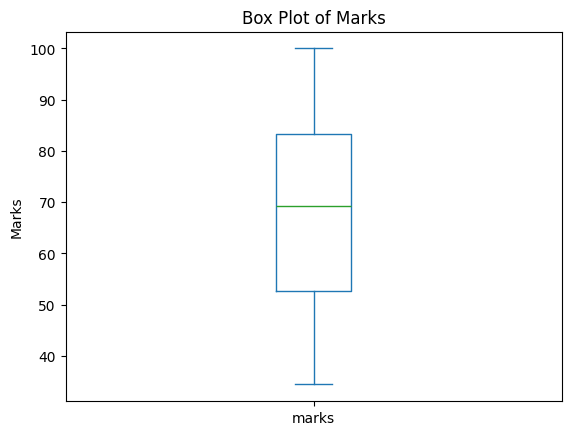

In [4]:
df_clean["marks"].plot(kind="box")
plt.title("Box Plot of Marks")
plt.ylabel("Marks")
plt.show()

**Explanation**

- `df_clean["marks"]` selects the column.
- `.plot(kind="box")` draws the box plot.
- Look at the line in the middle of the box. That is the median marks.

### 2.2 Box plots grouped by a category

Now we compare groups. For example: how are marks spread for each grade?

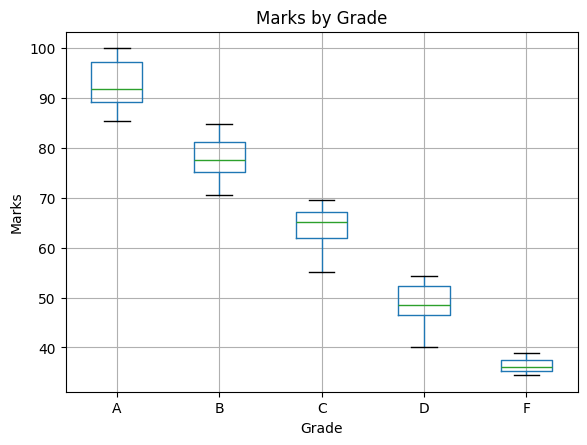

In [7]:
df_clean.boxplot(column="marks", by="grade")
plt.suptitle("")
plt.title("Marks by Grade")
plt.xlabel("Grade")
plt.ylabel("Marks")
plt.show()

**Explanation**

- `df_clean.boxplot(column="marks", by="grade")` draws one box for every grade.
- `plt.suptitle("")` removes the extra automatic title that pandas adds.
- Grade A should be at the top with the highest marks. If not, something is wrong with the data.

## Part 3: Histograms

### What does it show?

A histogram shows the **shape of one continuous variable**. It divides the values into ranges (called **bins**) and shows how many students fall in each range.

### When do we use it?

- To see where most values are.
- To see if the data is balanced or tilted to one side.


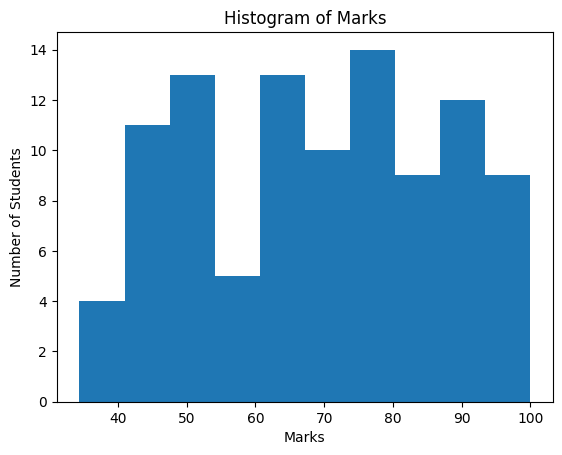

In [10]:
df_clean["marks"].plot(kind="hist", bins=10)
plt.title("Histogram of Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.show()

**Explanation**

- `kind="hist"` draws the histogram.
- `bins=10` means 10 bars. Each bar is one range of marks.
- A taller bar means more students in that range.

## Part 4: Count Plots and Bar Charts

These two look similar, but they answer different questions.

| Plot | Question it answers | Example |
|---|---|---|
| **Count plot** | How **many** students are in each category? | Number of students in each section |
| **Bar chart** | What is the **average (or total)** of a number for each category? | Average marks for each section |

### 4.1 Count plot

We count the categories using `value_counts()` and then draw bars.

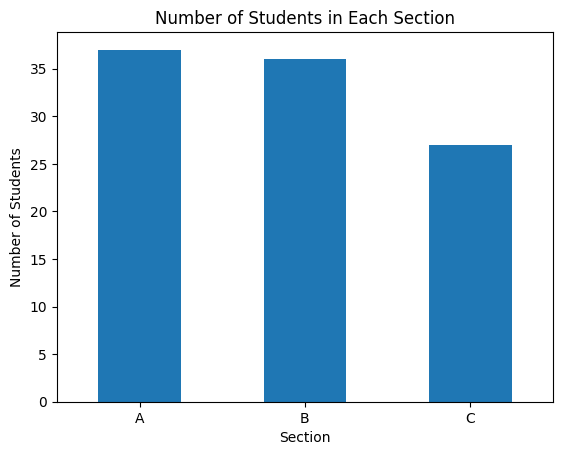

In [16]:
df_clean["section"].value_counts().plot(kind="bar")
plt.title("Number of Students in Each Section")
plt.xlabel("Section")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

**Explanation**

- `value_counts()` counts the students in each section.
- `.plot(kind="bar")` draws one bar for each section.
- `plt.xticks(rotation=0)` keeps the labels on the x-axis straight (not tilted).

### 4.2 Grouped bar chart

A grouped bar chart has **two categories** at the same time. Example: average marks by grade **and** gender. Each grade gets two bars, one for each gender.

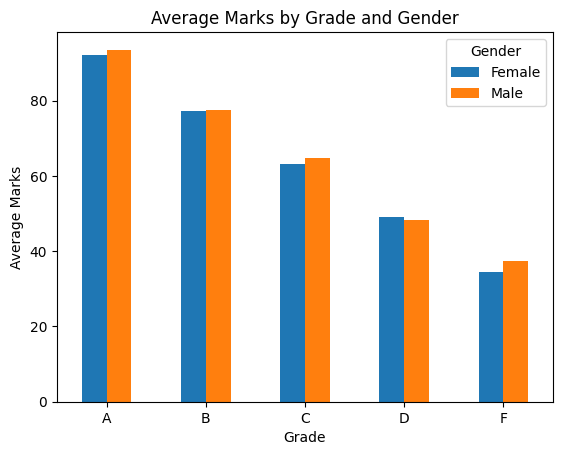

In [21]:
df_clean.groupby(["grade", "gender"])["marks"].mean().unstack().plot(kind="bar")
plt.title("Average Marks by Grade and Gender")
plt.xlabel("Grade")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.show()

## Part 6: Scatter Plots

### What does it show?

A scatter plot shows the **relationship between two continuous variables**. Each dot is one student.

### How to read it

| Pattern of dots | Meaning |
|---|---|
| Going **up** from left to right | Positive relationship |
| Going **down** from left to right | Negative relationship |
| No direction | No clear relationship |

### 6.1 Basic scatter plot

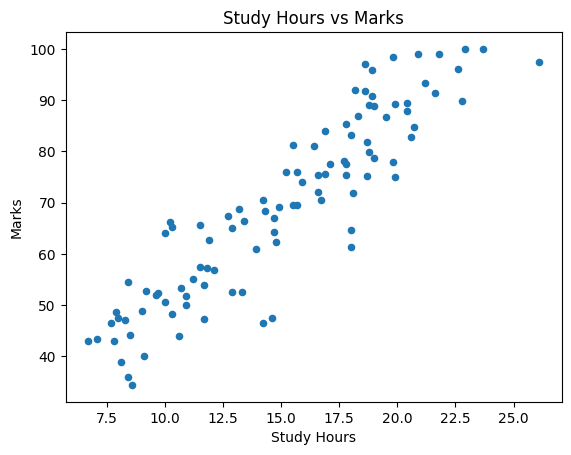

In [23]:
df_clean.plot(kind="scatter", x="study_hours", y="marks")
plt.title("Study Hours vs Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.show()

**Explanation:** `x` is the variable on the horizontal axis and `y` is on the vertical axis. We want to know: do more study hours lead to more marks?

## Part 7: Pie Charts

### What does it show?

A pie chart shows **how a whole is divided** into parts. Each slice is the share of one category.

### When does it work?

- When there are **few categories** (2 to 5).
- When we want to show **parts of a whole**.

### When does it not work?

- When there are **many categories**. Small slices are hard to compare. Use a bar chart instead.

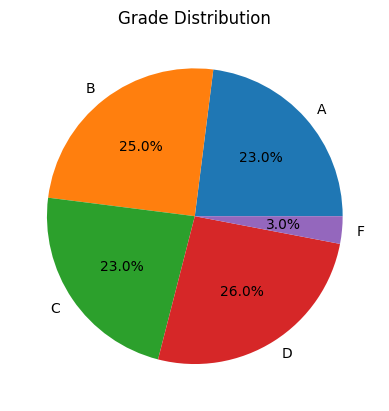

In [26]:
df_clean["grade"].value_counts().sort_index().plot(kind="pie", autopct="%1.1f%%")
plt.title("Grade Distribution")
plt.ylabel("")
plt.show()

**Explanation**

- `kind="pie"` draws the pie chart.
- `autopct="%1.1f%%"` writes the percent on each slice.
- `plt.ylabel("")` removes the extra label.

## Part 8: Pair Plot and Correlation Heatmap

When we have many continuous variables, we want to see **all relationships together**.

### 8.1 Pair plot

A pair plot draws a **scatter plot for every pair** of variables. On the diagonal it shows the histogram of each variable.

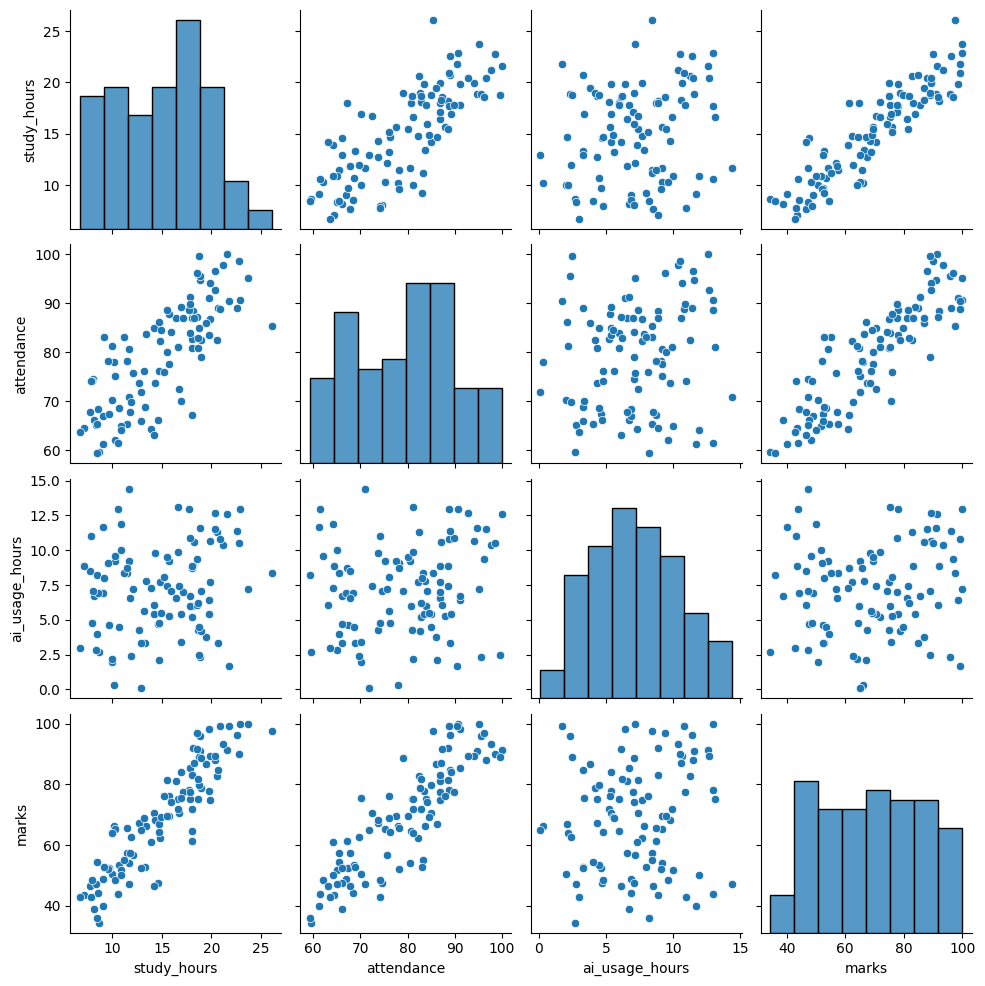

In [28]:
sns.pairplot(df_clean[["study_hours", "attendance", "ai_usage_hours", "marks"]])
plt.show()

### Pair plot with colour

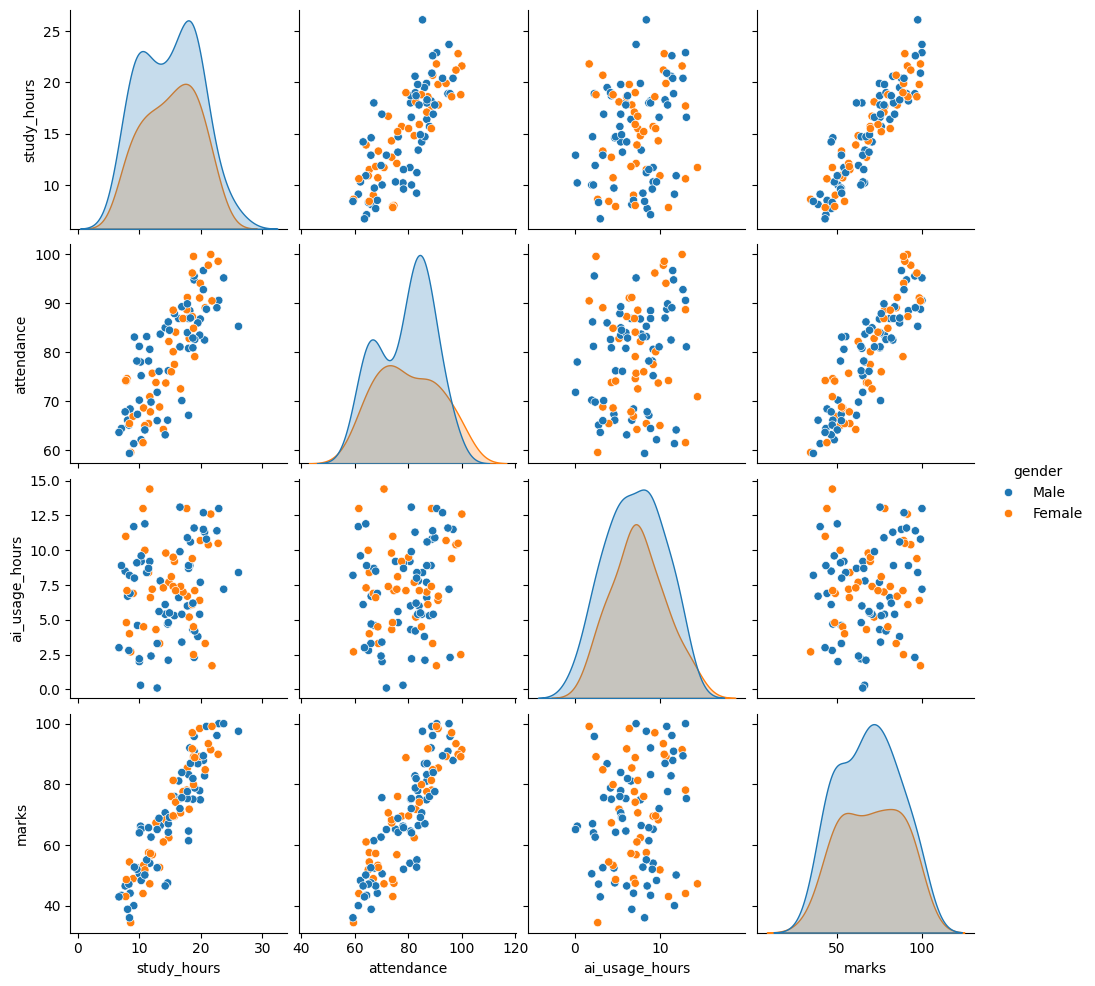

In [29]:
sns.pairplot(df_clean[["study_hours", "attendance", "ai_usage_hours", "marks", "gender"]], hue="gender")
plt.show()

**Explanation:** `hue="gender"` colours the dots by gender in every small plot.

## Part 9: Choosing the Right Plot

### Decision table: question to plot

| My question | Variable type | Best plot |
|---|---|---|
| What is the spread and are there outliers? | One continuous | Box plot |
| What is the shape of the data? | One continuous | Histogram |
| How many in each category? | One categorical | Count plot (bar of `value_counts`) |
| Compare an average across categories | Categorical and continuous | Bar chart |
| Compare spread across categories | Categorical and continuous | Grouped box plot |
| How does a value change in order or time? | Ordered data | Line plot |
| Are two numbers related? | Two continuous | Scatter plot |
| What share does each part have? (few parts) | One categorical | Pie chart |
| All relationships between many numbers | Many continuous | Pair plot |
| Strength of relationships at a glance | Many continuous | Correlation heatmap |